In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Load the dataset
df = pd.read_csv("datasets/student_performance/student_data.csv")

# Check the first few rows and the shape of the dataset
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
# Select a single input feature (X) and our target variable (y)
X = df[["G2"]]  # Double brackets keep it as a 2D DataFrame
y = df["G3"]    # 1D Series for our target

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 1)
y shape: (395,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (316, 1)
Testing features shape: (79, 1)
Training target shape: (316,)
Testing target shape: (79,)


In [5]:
from sklearn.linear_model import LinearRegression

# 1. Initialize the model
model = LinearRegression()

# 2. Train (fit) the model on the training data
model.fit(X_train, y_train)

# 3. Print the learned parameters (Slope and Intercept)
print("Learned Slope (Coefficient):", model.coef_[0])
print("Learned Intercept:", model.intercept_)

Learned Slope (Coefficient): 1.109625896944336
Learned Intercept: -1.4936733199830226


In [6]:
# 1. Generate predictions on the test set
y_pred = model.predict(X_test)

# 2. Compare the first 5 actual grades vs. predicted grades side-by-side
comparison = pd.DataFrame({
    "Actual (y_test)": y_test.values[:5],
    "Predicted (y_pred)": y_pred[:5]
})

print(comparison)

   Actual (y_test)  Predicted (y_pred)
0               10            7.383334
1               12           11.821837
2                5            4.054456
3               10            8.492960
4                9            8.492960


In [9]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error , mean_squared_error

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mse = rmse ** 2

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


MAE  : 1.2087
MSE  : 4.2162
RMSE : 2.0533
R²   : 0.7944


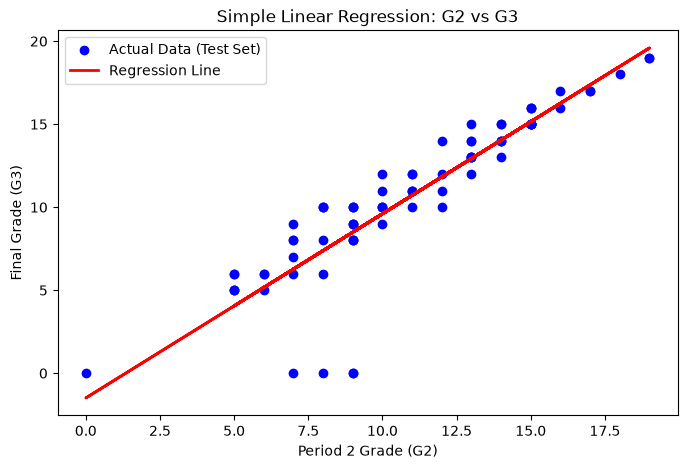

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

# Plot the actual test data points
plt.scatter(X_test, y_test, color="blue", label="Actual Data (Test Set)")

# Plot the model's regression line (predictions)
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Regression Line")

plt.xlabel("Period 2 Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.title("Simple Linear Regression: G2 vs G3")
plt.legend()
plt.show()